In [18]:
!pip install networkx

In [ ]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

In [20]:
df_raw = pd.read_csv('compras_ecommerce.csv')
df_raw.head()

,ID_Transaccion,Producto
0,TKT-00181,Teclado Mecánico RGB
1,TKT-01162,"Monitor 27"" 144Hz"
2,TKT-00840,Silla Gamer Ergonómica
3,TKT-01734,silla gamer ergonómica
4,TKT-01899,Mousepad XL


#### FASE 1: Data cleaning

Al igual que en la vida real, los datos del servidor tienen errores. Utilicen pandas para limpiarlos:

1. Eliminen cualquier fila donde el nombre del producto sea nulo.
2. Estandaricen el formato (todo a MAYÚSCULAS) porque el sistema capturó "Laptop" y "laptop" como cosas distintas.
3. El sistema falló algunas veces y guardó el ticket como "ERR_TIMEOUT". Eliminen esas transacciones.
4. Regla de Negocio (Self-Loops): Si un cliente compró 2 "Teclados" en el mismo ticket por error (filas duplicadas en el mismo ID de Transacción), deben eliminar el duplicado. Para la red, solo nos importa qué productos distintos acompañan a otros, un producto no puede acompañarse a sí mismo.

In [21]:
# 1. Eliminar valores nulos
df = df_raw.dropna(subset=['Producto']).copy()

# 2. Convertir a mayusculas
df['Producto'] = df['Producto'].str.upper()

# 3. ERR_TIMEOUT
df = df[df['ID_Transaccion'] != 'ERR_TIMEOUT'].copy()

# 4. Self loops
df = df.drop_duplicates(subset=['ID_Transaccion', 'Producto']).copy()

df.head()

,ID_Transaccion,Producto
0,TKT-00181,TECLADO MECÁNICO RGB
1,TKT-01162,"MONITOR 27"" 144HZ"
2,TKT-00840,SILLA GAMER ERGONÓMICA
3,TKT-01734,SILLA GAMER ERGONÓMICA
4,TKT-01899,MOUSEPAD XL


In [22]:
df.count()

ID_Transaccion    6258
Producto          6258
dtype: int64

#### Fase 2: Extracción

Tienen una tabla bipartita implícita (Tickets -> Productos). Deben colapsarla para conectar Producto -> Producto.

1. Utilicen pd.merge() para unir su dataframe limpio consigo mismo utilizando ID_Transaccion como llave de cruce.
2. Filtren la tabla resultante para eliminar las conexiones de un producto consigo mismo, y eviten aristas duplicadas (no queremos contar "Mouse-Laptop" y luego "Laptop-Mouse" por separado).
3. Agrupen (groupby) el resultado para contar cuántas veces ocurrió cada par. Ese conteo será su columna Peso.

In [ ]:
# 1. Merge del dataframe consigo mismo utilizando ID_Transaccion
union_productos = pd.merge(df, df, on='ID_Transaccion', how='inner')
union_productos.head(20)

,ID_Transaccion,Producto_x,Producto_y
0,TKT-00181,TECLADO MECÁNICO RGB,TECLADO MECÁNICO RGB
1,TKT-00181,TECLADO MECÁNICO RGB,"MONITOR 27"" 144HZ"
2,TKT-00181,TECLADO MECÁNICO RGB,MOUSEPAD XL
3,TKT-00181,TECLADO MECÁNICO RGB,SILLA GAMER ERGONÓMICA
4,TKT-01162,"MONITOR 27"" 144HZ","MONITOR 27"" 144HZ"
5,TKT-01162,"MONITOR 27"" 144HZ",MOUSEPAD XL
6,TKT-01162,"MONITOR 27"" 144HZ",SILLA GAMER ERGONÓMICA
7,TKT-00840,SILLA GAMER ERGONÓMICA,SILLA GAMER ERGONÓMICA
8,TKT-00840,SILLA GAMER ERGONÓMICA,TECLADO MECÁNICO RGB
9,TKT-01734,SILLA GAMER ERGONÓMICA,SILLA GAMER ERGONÓMICA


In [40]:
#2. Quitar self loops
aristas = union_productos[union_productos['Producto_x'] < union_productos['Producto_y']].copy()

# 3. Contar ocurrencias de cada par
interacciones = (
    aristas.groupby(['Producto_x', 'Producto_y'])
           .size()
           .reset_index(name='Peso')
           .sort_values('Peso', ascending=False)
           .reset_index(drop=True)
)
interacciones.head(20)

,Producto_x,Producto_y,Peso
0,AUDÍFONOS BLUETOOTH,WEBCAM 1080P,364
1,MOUSE INALÁMBRICO,WEBCAM 1080P,361
2,MOUSEPAD XL,TECLADO MECÁNICO RGB,359
3,"MONITOR 27"" 144HZ",MOUSEPAD XL,358
4,SILLA GAMER ERGONÓMICA,TECLADO MECÁNICO RGB,351
5,LAPTOP PRO 15,WEBCAM 1080P,351
6,"MONITOR 27"" 144HZ",TECLADO MECÁNICO RGB,350
7,LAPTOP PRO 15,MOUSE INALÁMBRICO,347
8,MOUSEPAD XL,SILLA GAMER ERGONÓMICA,346
9,AUDÍFONOS BLUETOOTH,LAPTOP PRO 15,341


#### FASE 3: El veredicto

Pasen su tabla extraída a networkx (nx.from_pandas_edgelist) y respondan mediante código a su director de ventas:

- **La Joya de la Corona:** Usando la métrica de Degree Centrality (nx.degree_centrality), ¿Cuál es el "Producto Ancla" o "Hub" de su tienda? (Este es el producto que deben poner en la portada de la página web porque es el que más incita a comprar otras cosas).
- **El Algoritmo en Acción:** Revisen los pesos de sus aristas (o el diccionario de vecinos del grafo). Si un cliente acaba de meter un "TECLADO MECÁNICO RGB" a su carrito, ¿cuál es el producto exacto que el sistema debe recomendarle automáticamente para maximizar la probabilidad de venta conjunta?
- **Renderizado:** Dibujen el grafo, haciendo que el grosor de las líneas (width) sea proporcional al Peso de la conexión. Visualmente comprobarán su algoritmo.

In [ ]:
# 1. degree centrality
G = nx.from_pandas_edgelist(interacciones, source='Producto_x', target='Producto_y', edge_attr='Peso')

centralidad = nx.degree_centrality(G)
ranking = pd.Series(centralidad).sort_values(ascending=False)
print(ranking.head(10))

hub = ranking.idxmax()
print(f"\nProducto Ancla (portada web): {hub}  (centralidad = {ranking.max():.3f})")

AUDÍFONOS BLUETOOTH         1.0
WEBCAM 1080P                1.0
MOUSE INALÁMBRICO           1.0
MOUSEPAD XL                 1.0
TECLADO MECÁNICO RGB        1.0
MONITOR 27" 144HZ           1.0
SILLA GAMER ERGONÓMICA      1.0
LAPTOP PRO 15               1.0
MICRÓFONO DE CONDENSADOR    1.0
CABLE HDMI 2.1              1.0
dtype: float64

Producto Ancla (portada web): AUDÍFONOS BLUETOOTH  (centralidad = 1.000)


In [42]:
#2. Recomendacion 
producto = 'TECLADO MECÁNICO RGB'  

if producto in G:
    vecinos = G[producto]  
    recomendado = max(vecinos, key=lambda v: vecinos[v]['Peso'])
    print(f"Recomendar con {producto}: {recomendado} (comprados juntos {vecinos[recomendado]['Peso']} veces)")
    print("\nTop vecinos:")
    for v, d in sorted(vecinos.items(), key=lambda x: x[1]['Peso'], reverse=True)[:5]:
        print(f"  {v}: {d['Peso']}")
else:
    print("No encontré ese nombre exacto. Productos disponibles:")
    print(sorted(G.nodes()))

Recomendar con TECLADO MECÁNICO RGB: MOUSEPAD XL (comprados juntos 359 veces)

Top vecinos:
  MOUSEPAD XL: 359
  SILLA GAMER ERGONÓMICA: 351
  MONITOR 27" 144HZ: 350
  MOUSE INALÁMBRICO: 37
  WEBCAM 1080P: 34


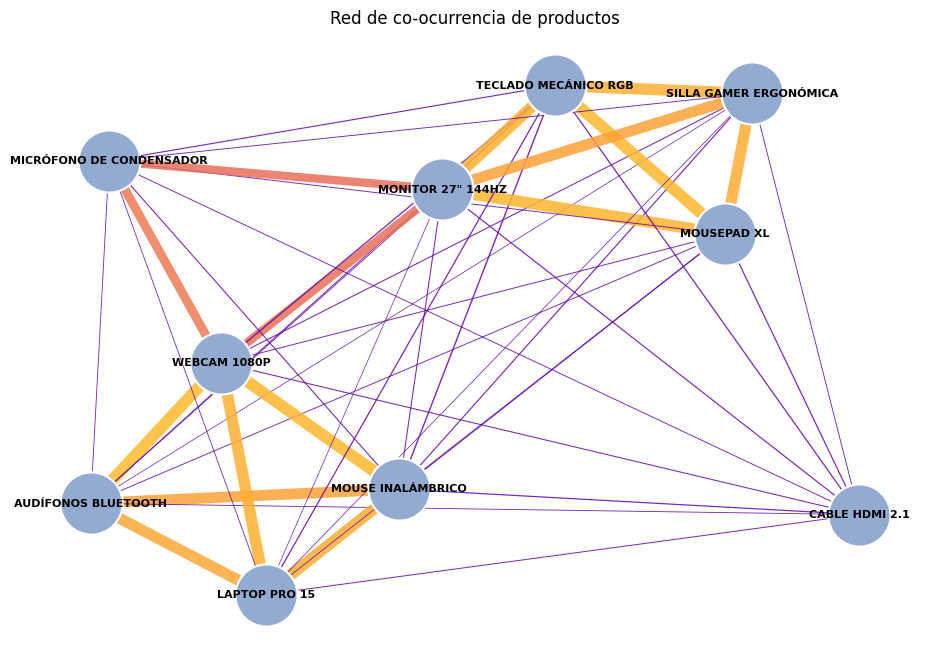

In [53]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import networkx as nx

pesos = np.array([G[u][v]['Peso'] for u, v in G.edges()])
norm = mcolors.Normalize(vmin=pesos.min(), vmax=pesos.max())

anchos = 0.5 + 8 * norm(pesos)
colores = cm.plasma(0.15 + 0.7 * norm(pesos))  

pos = nx.spring_layout(G, seed=42, weight='Peso', k=1.2)

plt.figure(figsize=(12, 8))
nx.draw_networkx_edges(G, pos, width=anchos, edge_color=colores, alpha=0.85)
nx.draw_networkx_nodes(G, pos, node_size=2000, node_color="#94ABD1",
                       edgecolors='white', linewidths=1.5)
nx.draw_networkx_labels(G, pos, font_size=8, font_color='black', font_weight='bold')
plt.title('Red de co-ocurrencia de productos')
plt.axis('off')
plt.show()